<a href="https://colab.research.google.com/github/nhunghoang/agentp/blob/agentp-update-20261105/example/colab_example.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AGENT-P example run

**AGENT-P** runs transcriptome-wide association studies (TWAS) of brain phenotypes. It predicts genetically regulated gene expression (GREx) in eight brain regions with four model sets — PrediXcan (`PDX`), UTMOST (`UTM`), JTI (`JTI`), FUSION (`FUS`) — and tests the predicted GREx for association with a phenotype in two ways:

* **Genotype-level TWAS**: from individual-level genotypes, covariates, and phenotypes
* **Summary-level TWAS**: from GWAS summary statistics

**In this example**, AGENT-P predicts GREx in the **caudate** with the **JTI** models and tests it for association with **amygdala volume** in an example cohort of 2,000 subjects, using both genotype-level and summary-level TWAS.

It then plots the TWAS p-values: a Manhattan plot of the genotype-level TWAS, and a Miami plot comparing summary-level TWAS (top) with genotype-level TWAS (bottom).

The run takes about 15–20 minutes on a free Colab runtime: **Runtime → Run all**.

## 1. Install

AGENT-P runs in its own conda environment (Python 3.10 with plink2, bgenix, and R for FUSION), separate from Colab's own Python. This cell downloads the AGENT-P code from GitHub and creates the environment with micromamba (about 5–8 minutes).

In [2]:
%%bash
set -e
BRANCH=agentp-update-20261105

## AGENT-P code and example data (the full models in Git LFS are not needed here)
[ -d agentp ] || GIT_LFS_SKIP_SMUDGE=1 git clone -q --depth 1 -b $BRANCH https://github.com/nhunghoang/agentp.git

## conda environment with micromamba: Python packages, plink2, bgenix, and R for FUSION
export MAMBA_ROOT_PREFIX=$PWD/mamba
[ -x bin/micromamba ] || curl -Ls https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xj bin/micromamba
[ -d agentp_env ] || bin/micromamba create -y -q -p $PWD/agentp_env -c conda-forge -c bioconda --override-channels \
    python=3.10 "numpy<2" pandas "scipy>=1.11" statsmodels h5py patsy bitarray matplotlib bgen-reader pyliftover pip \
    plink2=2.00a5.12 bgenix=1.1.7 \
    r-base=4.2 r-optparse r-rcolorbrewer r-rcpp r-rcppeigen compilers

## plink2R (used by FUSION; not on conda)
PATH=$PWD/agentp_env/bin:$PATH R CMD INSTALL agentp/agentp/external/plink2R/plink2R > plink2R_install.log 2>&1 \
    || { tail -20 plink2R_install.log; exit 1; }

## Download AGENT-P package
agentp_env/bin/pip install -q --no-deps -e agentp
agentp_env/bin/python -c "import agentp; print('AGENT-P installed from', agentp.__path__[0])"
agentp_env/bin/Rscript -e 'suppressMessages(library(plink2R)); cat("R and plink2R ready\n")'

AGENT-P installed from /content/agentp
R and plink2R ready


The next cell is set-up only: it lets the cells below that start with `%%agentp` run in AGENT-P's environment (installed above), from the `agentp/example` folder. Each of these cells starts a new Python process, so each one first imports AGENT-P and loads the example project.

In [3]:
import os, subprocess
from IPython.core.magic import register_cell_magic

ROOT = os.getcwd()
ENV = f'{ROOT}/agentp_env'
EXAMPLE = f'{ROOT}/agentp/example'

## AGENT-P's environment first on PATH (python, plink2, bgenix); no Colab Python settings
RUN_ENV = {k: v for k, v in os.environ.items() if k not in ('PYTHONPATH', 'MPLBACKEND')}
RUN_ENV.update(PATH=f'{ENV}/bin:' + os.environ['PATH'], MPLBACKEND='Agg')

@register_cell_magic
def agentp(line, cell):
    '''Run this cell with AGENT-P's Python, from the example folder, and show its output.'''
    proc = subprocess.Popen([f'{ENV}/bin/python', '-u', '-c', cell], cwd=EXAMPLE, env=RUN_ENV,
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for out in proc.stdout:
        print(out, end='')
    if proc.wait() != 0:
        raise RuntimeError('This AGENT-P step failed: see the output above')

print(subprocess.run('plink2 --version; bgenix -help | head -1', shell=True, env=RUN_ENV,
                     capture_output=True, text=True).stdout)

PLINK v2.00a5.12LM 64-bit Intel (25 Jun 2024)
Usage: bgenix <options>



## 2. Create the project

A **project** is a folder that holds the inputs and results of one analysis. The example cohort has 2,000 subjects:

* `subjects.txt`: subject IDs
* `covariates.csv`: age, sex, and 3 genetic principal components
* `volumes.csv`: four brain volumes (putamen, amygdala, hippocampus, caudate)
* `genotypes/test_c*.bgen`: genotypes for chromosomes 1–22, which AGENT-P quality-controls with plink2

`set_models_dir('example_models')` selects the small example models (caudate only) that come with the repository; real analyses use the full models (see the README).

In [4]:
%%agentp
from agentp import Project, set_models_dir
set_models_dir('example_models')

project = Project('example_run')
project.set_subjects('example_data/subjects.txt')
project.add_covariates('example_data/covariates.csv')
project.add_phenotypes('example_data/volumes.csv')
project.add_genotypes('example_data/genotypes', 'test_c*.bgen')


> Using models in /content/agentp/example/example_models

> Created new project directory:
    /content/agentp/example/example_run


> Saved 2000 IDs from example_data/subjects.txt


> Added 5 covariates to this project


> Parsing phenotype data...
    Added "putamen_volume" phenotype to this project
    Added "amygdala_volume" phenotype to this project
    Added "hippocampus_volume" phenotype to this project
    Added "caudate_volume" phenotype to this project


> Extracting project cohort from chromosome 1...
    2000 samples (1012 females, 988 males; 2000 founders) loaded.
    9976 variants loaded.
    --keep: 2000 samples remaining.
    2000 samples (1012 females, 988 males; 2000 founders) remaining after main filters.
    9976 variants remaining after main filters.


> Extracting project cohort from chromosome 2...
    2000 samples (1012 females, 988 males; 2000 founders) loaded.
    9996 variants loaded.
    --keep: 2000 samples remaining.
    2000 samples (1012 females, 988 ma

## 3. Summary-level TWAS

Summary-level TWAS combines GWAS summary statistics with the GREx model weights and the LD between the model SNPs. Here, the input is a GWAS of amygdala volume in the example cohort (`amygdala_volume_gwas.regenie.gz`, made with REGENIE), and the models are the JTI caudate models.

In [5]:
%%agentp
from agentp import Project, SummaryTWAS, set_models_dir
set_models_dir('example_models')
project = Project('example_run')

stwas = SummaryTWAS(project, 'JTI', 'caudate')
stwas.add_gwas('amygdala_volume', 'example_data/amygdala_volume_gwas.regenie.gz')
stwas.run_twas('amygdala_volume')


> Using models in /content/agentp/example/example_models

> Project already exists. Results will be saved to:
    /content/agentp/example/example_run

> Running sTWAS on "amygdala_volume" using JTI caudate models...
    10 % of model's snps found so far in the gwas study
    20 % of model's snps found so far in the gwas study
    30 % of model's snps found so far in the gwas study
    40 % of model's snps found so far in the gwas study
    50 % of model's snps found so far in the gwas study
    60 % of model's snps found so far in the gwas study
    70 % of model's snps found so far in the gwas study
    80 % of model's snps found so far in the gwas study
    90 % of model's snps found so far in the gwas study
    92 % of model's snps used



## 4. Genotype-level TWAS

Genotype-level TWAS first predicts caudate GREx for every subject from their genotypes (`predict_grex`), then tests each gene's GREx for association with amygdala volume, adjusting for the covariates (`run_twas`).

In [6]:
%%agentp
from agentp import Project, IndividualTWAS, set_models_dir
set_models_dir('example_models')
project = Project('example_run')

itwas = IndividualTWAS(project, 'JTI', 'caudate')
itwas.predict_grex()
itwas.run_twas('amygdala_volume')


> Using models in /content/agentp/example/example_models

> Project already exists. Results will be saved to:
    /content/agentp/example/example_run

> Filtering genotypes to TWAS SNPs...

    Converting genotypes to dosages:

    Chr 1 contains 9449 variants
    -- 1 blocks across 1 multi-threaded runs expected
    processing chr 1 block 0...
    done converting chr 1.0
    > 0 hr 0 mn 35 sc < for this run
    combined all blocks into one file (0 hr 0 mn 2 sc)

    Chr 2 contains 9549 variants
    -- 1 blocks across 1 multi-threaded runs expected
    processing chr 2 block 0...
    done converting chr 2.0
    > 0 hr 0 mn 35 sc < for this run
    combined all blocks into one file (0 hr 0 mn 3 sc)

    Chr 3 contains 9593 variants
    -- 1 blocks across 1 multi-threaded runs expected
    processing chr 3 block 0...
    done converting chr 3.0
    > 0 hr 0 mn 39 sc < for this run
    combined all blocks into one file (0 hr 0 mn 2 sc)

    Chr 4 contains 9536 variants
    -- 1 blocks ac

## 5. Results

Each TWAS writes one table per phenotype: example_run/sTWAS/JTI_caudate/amygdala_volume.csv and example_run/iTWAS/JTI_caudate/amygdala_volume.csv.

The table below shows the 10 top genes of the summary-level TWAS (smallest p-values), with their results in both TWAS side by side.

In [7]:
import pandas as pd

MODEL = 'JTI_caudate'   # results folder: change to PDX_caudate, UTM_caudate, or FUS_caudate for other model sets

res = {t: pd.read_csv(f'{EXAMPLE}/example_run/{t}/{MODEL}/amygdala_volume.csv', sep='\t')
       for t in ['sTWAS', 'iTWAS']}
for t, name in [('sTWAS', 'Summary-level TWAS'), ('iTWAS', 'Genotype-level TWAS')]:
    df = res[t]
    bonf = 0.05 / len(df)
    print(f'{name}: {len(df)} genes tested, {(df.pvalue < bonf).sum()} with p < {bonf:.1e} (Bonferroni)')

## FUSION results have no gene_name column, so keep only the columns that exist
cols = [c for c in ['gene', 'gene_name', 'zscore', 'pvalue'] if c in res['sTWAS'].columns]
top = res['sTWAS'][cols] \
        .merge(res['iTWAS'][['gene', 'zscore', 'pvalue']], on='gene',
               suffixes=(' (summary-level)', ' (genotype-level)')) \
        .sort_values('pvalue (summary-level)').head(10).reset_index(drop=True)
top

Summary-level TWAS: 5000 genes tested, 0 with p < 1.0e-05 (Bonferroni)
Genotype-level TWAS: 4991 genes tested, 0 with p < 1.0e-05 (Bonferroni)


,gene,gene_name,zscore (summary-level),pvalue (summary-level),zscore (genotype-level),pvalue (genotype-level)
0,ENSG00000149599,DUSP15,3.768979,0.000164,-3.746980,0.000184
1,ENSG00000284428,AC092329.4,3.443600,0.000574,-3.351201,0.000820
2,ENSG00000183850,ZNF730,-3.443600,0.000574,3.351827,0.000818
3,ENSG00000267009,AC007780.1,3.408339,0.000654,-3.374456,0.000754
4,ENSG00000175315,CST6,-3.363182,0.000770,3.331136,0.000881
5,ENSG00000254855,AP001107.8,-3.363182,0.000770,3.331551,0.000879
6,ENSG00000277117,FP565260.3,-3.336390,0.000849,3.233927,0.001241
7,ENSG00000180008,SOCS4,-3.246924,0.001167,3.257165,0.001144
8,ENSG00000146574,CCZ1B,3.206928,0.001342,-3.061252,0.002233
9,ENSG00000135441,BLOC1S1,3.171450,0.001517,-2.894172,0.003843


With only 2,000 subjects, no gene passes the Bonferroni threshold in this example, but the two TWAS agree on the strongest genes (the summary TWAS uses a GWAS of the same cohort).

## 6. Plots

* **Manhattan plot**: genotype-level TWAS p-values by gene position; the dashed line is the Bonferroni threshold.
* **Miami plot**: summary-level TWAS (top) mirrored against genotype-level TWAS (bottom).

In [8]:
%%agentp
import os
from agentp import load_pvalues, manhattan_plot, miami_plot

s = load_pvalues('example_run/sTWAS/JTI_caudate/amygdala_volume.csv')
i = load_pvalues('example_run/iTWAS/JTI_caudate/amygdala_volume.csv')

os.makedirs('example_run/figures', exist_ok=True)
manhattan_plot(i, label='Individual TWAS (JTI caudate)', title='amygdala_volume',
               out_file='example_run/figures/manhattan.png')
miami_plot(s, i, top_label='Summary TWAS (JTI caudate)', bottom_label='Individual TWAS (JTI caudate)',
           title='amygdala_volume', out_file='example_run/figures/miami.png')


> Saved Manhattan plot to example_run/figures/manhattan.png

> Saved Miami plot to example_run/figures/miami.png


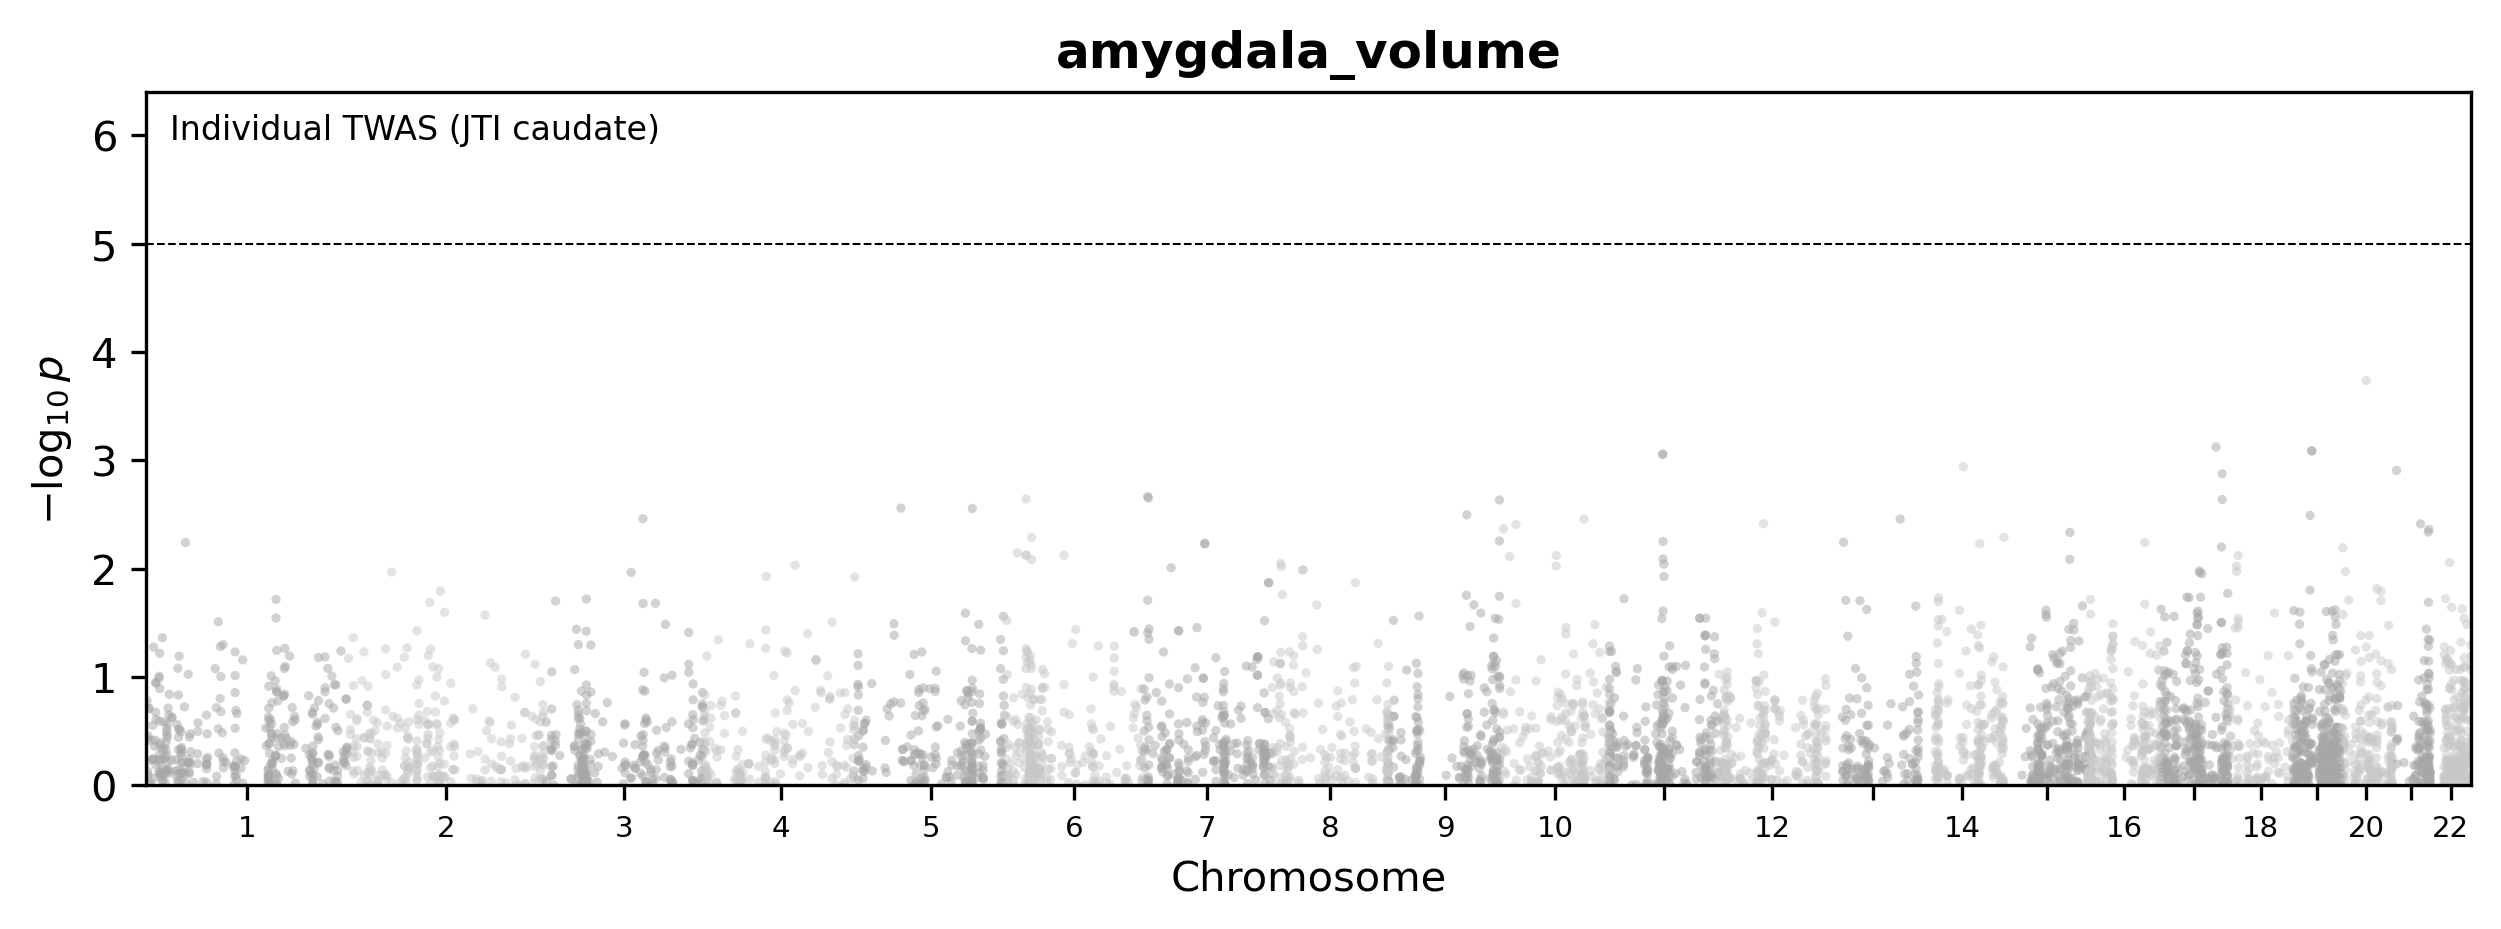

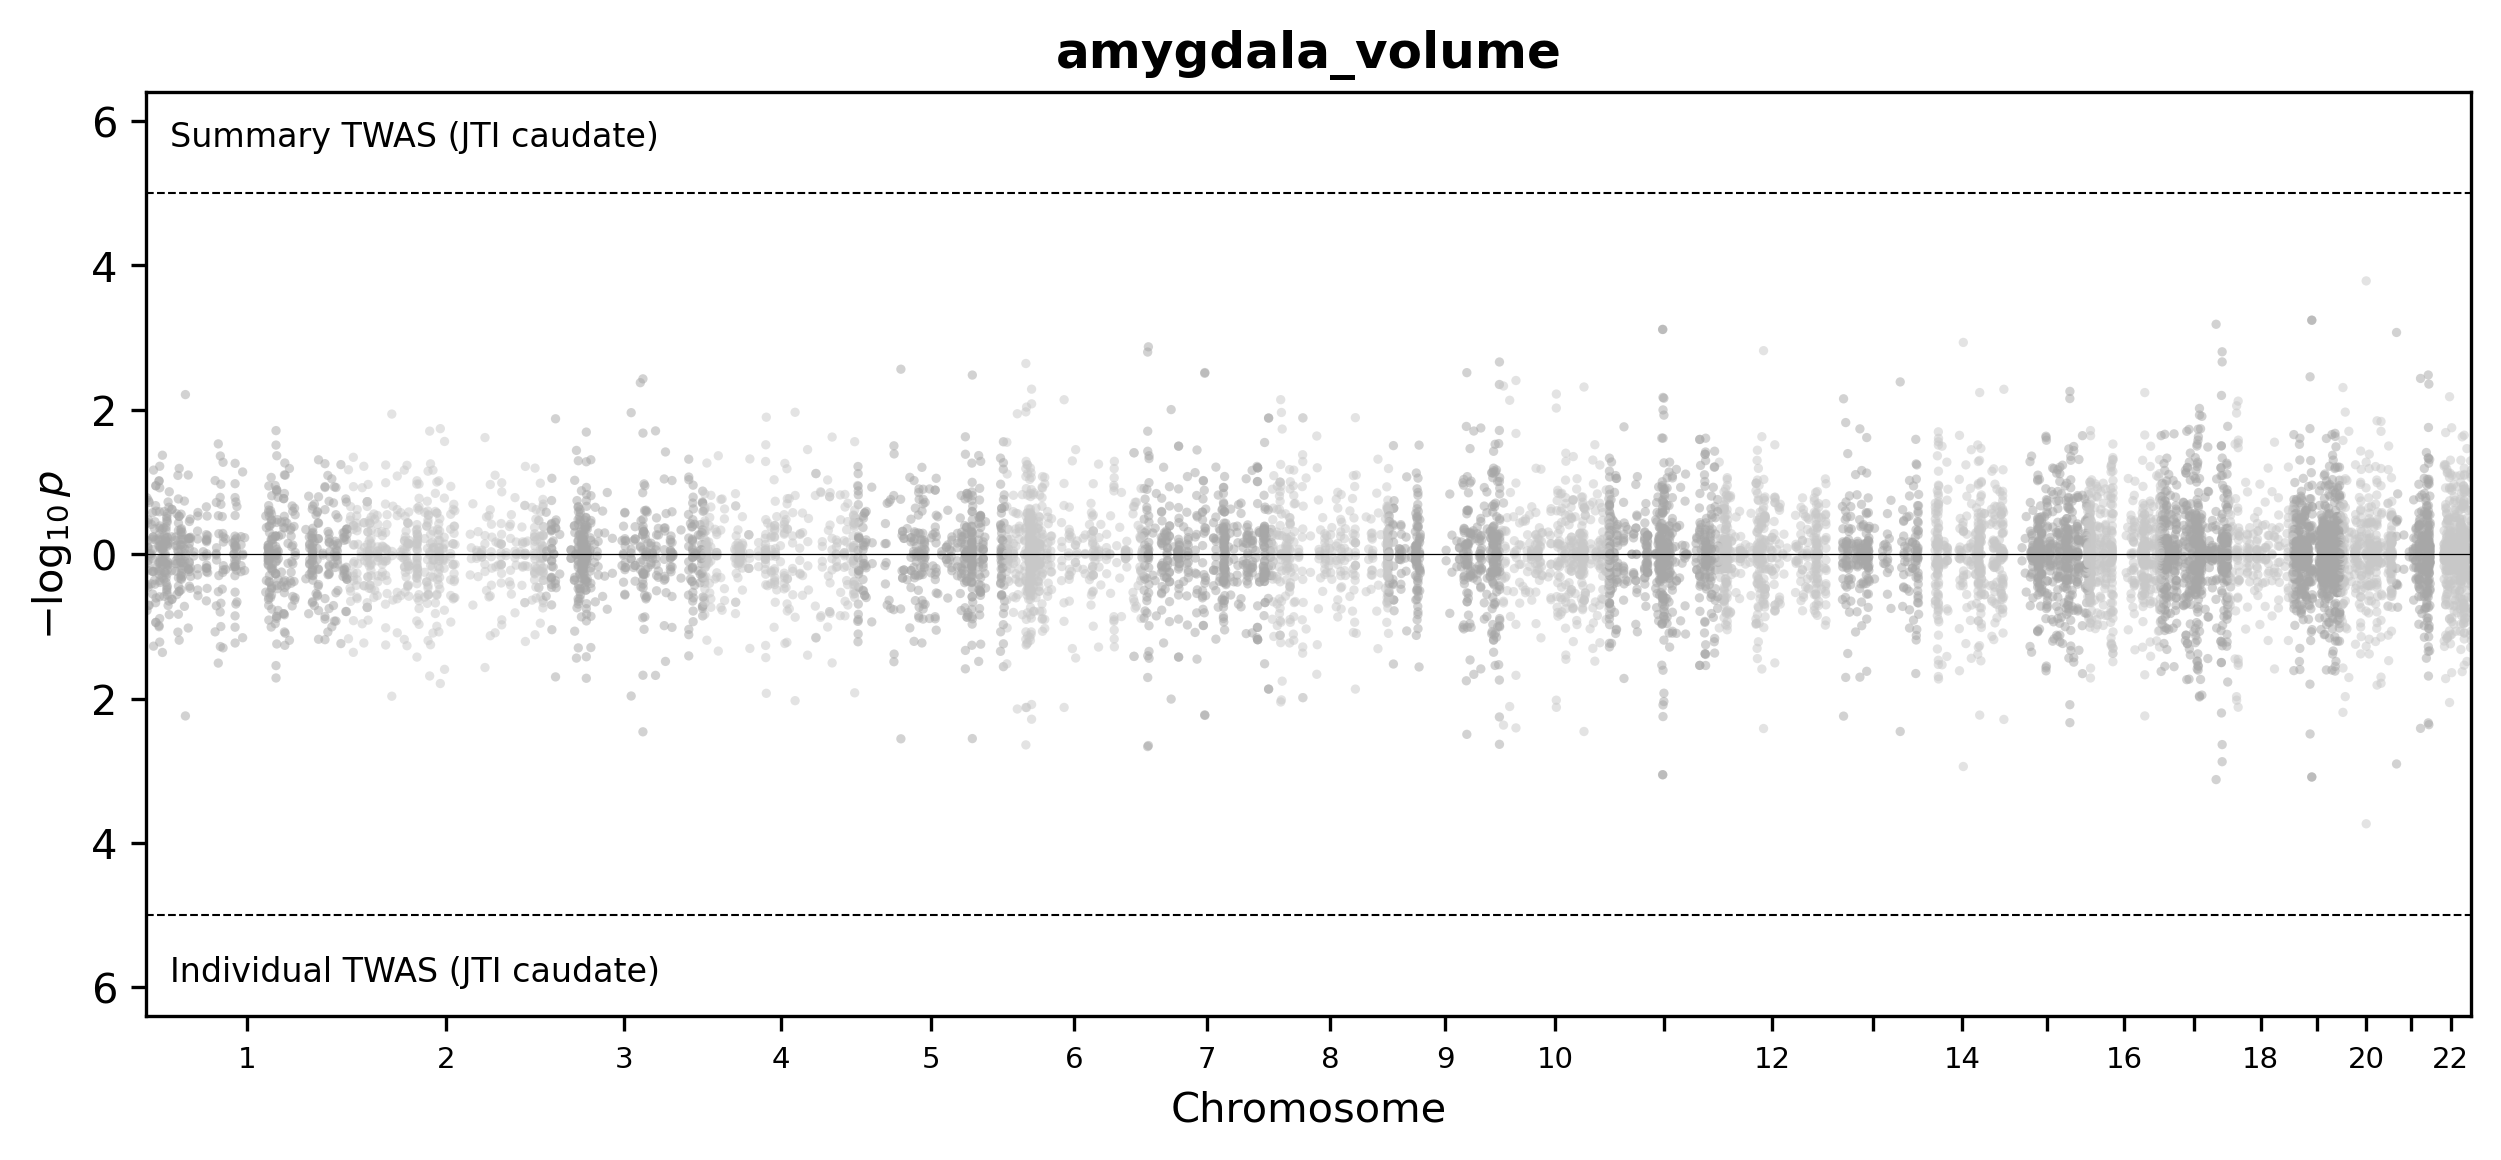

In [9]:
from IPython.display import Image, display
display(Image(f'{EXAMPLE}/example_run/figures/manhattan.png', width=900))
display(Image(f'{EXAMPLE}/example_run/figures/miami.png', width=900))

## Next steps

### What this example includes
This notebook uses only the small example data and models in the AGENT-P repository:
* **Data**: 2,000 example subjects (genotypes, covariates, and four brain volumes), plus a GWAS of amygdala volume in the same subjects
* **Models**: caudate models only (PrediXcan, UTMOST, JTI, FUSION)

### Try another model set
In the summary-level and genotype-level TWAS cells, replace `'JTI'` with another model set below. Then, in the results and plot cells, replace `JTI_caudate` in the file paths with the matching folder name.

| Model set | Code | Results folder |
|---|---|---|
| PrediXcan | `'PDX'` | `PDX_caudate` |
| UTMOST | `'UTM'` | `UTM_caudate` |
| JTI (used above) | `'JTI'` | `JTI_caudate` |
| FUSION | `'FUS'` | `FUS_caudate` |

For example, to use PrediXcan:
```python
stwas = SummaryTWAS(project, 'PDX', 'caudate')
```

### Test another phenotype
* **Genotype-level TWAS** can test any phenotype in the phenotype file. The example file has `putamen_volume`, `amygdala_volume`, `hippocampus_volume`, and `caudate_volume`. The predicted GREx is reused, so only the association test runs again:
  ```python
  itwas = IndividualTWAS(project, 'JTI', 'caudate')
  itwas.run_twas('hippocampus_volume')
  ```
* **Summary-level TWAS** needs GWAS summary statistics of the phenotype. The example data include a GWAS of amygdala volume only. With your own GWAS file:
  ```python
  stwas = SummaryTWAS(project, 'JTI', 'caudate')
  stwas.add_gwas('my_phenotype', 'my_gwas.regenie.gz')
  stwas.run_twas('my_phenotype')
  ```
  REGENIE output is read as it is. For other formats, give the column names to `add_gwas` (e.g. `snp_col='rsid', ref_col='a1', alt_col='a2', beta_col='beta', beta_se_col='se', pval_col='p'`).

### Analyze your own data
To run AGENT-P in all eight brain regions, you need:
1. **AGENT-P on your computer or cluster**:
   ```bash
   git clone https://github.com/nhunghoang/agentp.git && cd agentp
   conda env create -f environment.yml && conda activate agentp
   pip install --no-deps -e .
   ```
2. **The full models**: download [`models.tar.gz`](https://drive.google.com/file/d/1llysnSFOut3E_g1omlgQfi-N5fptuuLa/view?usp=sharing) (about 2 GB) and extract it into `agentp/models`. The models cover eight brain regions: `dlpfc`, `ant-cingulate`, `amygdala`, `hippocampus`, `caudate`, `putamen`, `nuc-accumbens`, `cerebellar-hemi`.
3. **Your own data**, either:
   * individual-level genotypes, covariates, and phenotypes, for genotype-level and summary-level TWAS; or
   * GWAS summary statistics only (e.g. public brain imaging GWAS), for summary-level TWAS.

Then run the same steps as in this notebook, without `set_models_dir('example_models')`.

### Run all models at once
Each model set gives its own p-value per gene. With the full models, `run_all_twas` runs every model set (4 methods × 8 brain regions), then combines the p-values of each gene into one with ACAT (Aggregated Cauchy Association Test):
```python
from agentp import Project, run_all_twas
project = Project('my_project')
run_all_twas(project, 'my_phenotype', twas_type='stwas',
             gwas_files={'my_phenotype': 'my_gwas.regenie.gz'})
```
The combined results are saved to `my_project/sTWAS/ACAT/my_phenotype.csv`. Use `twas_type='itwas'` for genotype-level TWAS.